In [56]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 1. IMPORT LIBRARIES AND SET STATIC VARIABLES

In [57]:
import pandas as pd
import numpy as np
# Plot Cumulative Returns
import matplotlib.pyplot as plt
from fredapi import Fred
import yfinance as yf
from scipy.optimize import minimize
import os
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from pathlib import Path


In [58]:
FED_API_KEY="79b300c57b4893f902328303a135d4a1"

# 2.INITIALIZE DATA 

In [59]:
import google.auth
from google.auth.transport.requests import AuthorizedSession

SHEET_ID = "1XKeBA6hcnPLcdPixX5bWBtbDTBWP-MtK7Av8ead0NN0"

credentials, _ = google.auth.default(
    scopes=["https://www.googleapis.com/auth/drive.readonly"]
)

print("Identité :", getattr(credentials, "service_account_email", "Autre"))

session = AuthorizedSession(credentials)

response = session.get(
    f"https://www.googleapis.com/drive/v3/files/{SHEET_ID}/export",
    params={
        "mimeType": "application/vnd.openxmlformats-officedocument.spreadsheetml.sheet"
    },
    timeout=120
)

print("HTTP :", response.status_code)
print("Réponse Google :", response.text[:2000] if not response.ok else "Accès OK")

Identité : 200307969304-compute@developer.gserviceaccount.com
HTTP : 200
Réponse Google : Accès OK


In [60]:
STRATEGY_SHEET_ID = '1XKeBA6hcnPLcdPixX5bWBtbDTBWP-MtK7Av8ead0NN0'

def reload_strategy_excel():
    credentials, _ = google.auth.default(
        scopes=['https://www.googleapis.com/auth/drive.readonly']
    )

    session = AuthorizedSession(credentials)

    response = session.get(
        f'https://www.googleapis.com/drive/v3/files/{STRATEGY_SHEET_ID}/export',
        params={
            'mimeType': 'application/vnd.openxmlformats-officedocument.spreadsheetml.sheet'
        },
        timeout=120
    )

    response.raise_for_status()

    print("STRATEGY_ANALYSIS rechargé avec succès")
    return BytesIO(response.content)

In [61]:
# Source : Google Sheets privé STRATEGY_ANALYSIS (authentification Google sur le Mac)
# Prérequis : pip install google-auth requests openpyxl
# Première connexion : gcloud auth application-default login --scopes=https://www.googleapis.com/auth/drive.readonly,https://www.googleapis.com/auth/cloud-platform
from io import BytesIO
import google.auth
from google.auth.transport.requests import AuthorizedSession

STRATEGY_SHEET_ID = '1XKeBA6hcnPLcdPixX5bWBtbDTBWP-MtK7Av8ead0NN0'
credentials, _ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive.readonly'])
session = AuthorizedSession(credentials)
response = session.get(
    f'https://www.googleapis.com/drive/v3/files/{STRATEGY_SHEET_ID}/export',
    params={'mimeType': 'application/vnd.openxmlformats-officedocument.spreadsheetml.sheet'},
    timeout=120,
)
response.raise_for_status()
strategy_excel = BytesIO(response.content)

data = pd.read_excel(strategy_excel, sheet_name='EQUITY BACKTEST STRATEGY', skiprows=2, usecols=[0, 1, 3])

In [62]:
data

,Date,Close,Close.1
0,1998-12-31 16:00:00.288,1229.40,1.1680
1,1999-01-08 16:00:00.288,1275.09,1.1580
2,1999-01-14 16:00:00.288,1212.19,1.1560
3,1999-01-22 16:00:00.288,1225.19,1.1585
4,1999-01-29 16:00:00.288,1279.64,1.1365
...,...,...,...
1447,2026-10-16 16:00:00.288,7659.44,1.1390
1448,2026-10-23 16:00:00.288,7623.68,1.1256
1449,NaT,NaN,1.1202
1450,NaT,NaN,1.1235


In [63]:
def convert_df_date(data):
    # Format the 'Date' column to show only the date (YYYY-MM-DD)
    data['Date'] = data['Date'].dt.strftime('%Y-%m-%d')
    # Set 'Date' as the index

    data.index=pd.to_datetime(data.index, errors='coerce')
    return data

In [64]:
# Format the 'Date' column to show only the date (YYYY-MM-DD)
data['Date'] = data['Date'].dt.strftime('%Y-%m-%d')
# Set 'Date' as the index
data.set_index('Date', inplace=True)
data.index=pd.to_datetime(data.index, errors='coerce')

# Rename columns 'Close' to 'SPX' and 'Close.1' to 'EURUSD'
data.rename(columns={'Close': 'SPX', 'Close.1': 'EURUSD'}, inplace=True)
data.dropna(inplace=True)

In [65]:
data.index

DatetimeIndex(['1998-12-31', '1999-01-08', '1999-01-14', '1999-01-22',
               '1999-01-29', '1999-02-05', '1999-02-12', '1999-02-19',
               '1999-02-26', '1999-03-05',
               ...
               '2026-08-21', '2026-08-28', '2026-09-04', '2026-09-11',
               '2026-09-18', '2026-09-25', '2026-10-02', '2026-10-09',
               '2026-10-16', '2026-10-23'],
              dtype='datetime64[ns]', name='Date', length=1449, freq=None)

In [66]:
# Assuming the DataFrame is called 'data', and it contains the 'SPX' column
DVIDEND_YIELD = 0.02  # Example: 2% annual dividend yield
initial_value = data['SPX'].iloc[0]  # Assume SPXTR starts equal to the first value of SPX

# Create SPXTR column and initialize the first value
data['SPXTR'] = 0
data.loc[data.index[0], 'SPXTR'] = initial_value

# Loop over rows to calculate SPXTR based on the formula provided
for i in range(1, len(data)):
    data.loc[data.index[i], 'SPXTR'] = data.loc[data.index[i-1], 'SPXTR'] * (
        1 + (data.loc[data.index[i], 'SPX'] - data.loc[data.index[i-1], 'SPX']) / data.loc[data.index[i-1], 'SPX'] 
        + DVIDEND_YIELD / 52
    )


/var/folders/2g/jybkt1rx3x731rqm3lckb_j80000gn/T/ipykernel_86963/309903971.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '1229.4' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  data.loc[data.index[0], 'SPXTR'] = initial_value


In [67]:
data

,SPX,EURUSD,SPXTR
Date,,,
1998-12-31,1229.40,1.1680,1229.400000
1999-01-08,1275.09,1.1580,1275.562846
1999-01-14,1212.19,1.1560,1213.130122
1999-01-22,1225.19,1.1585,1226.606793
1999-01-29,1279.64,1.1365,1281.591530
...,...,...,...
2026-09-25,7743.41,1.1613,13485.073710
2026-10-02,7722.72,1.1601,13454.228841
2026-10-09,7811.54,1.1479,13614.142368


In [68]:
# Create the TRCompo column by dividing SPXTR by EURUSD
data['TRCompo'] = data['SPXTR'] / data['EURUSD']

In [69]:
data

,SPX,EURUSD,SPXTR,TRCompo
Date,,,,
1998-12-31,1229.40,1.1680,1229.400000,1052.568493
1999-01-08,1275.09,1.1580,1275.562846,1101.522320
1999-01-14,1212.19,1.1560,1213.130122,1049.420521
1999-01-22,1225.19,1.1585,1226.606793,1058.788772
1999-01-29,1279.64,1.1365,1281.591530,1127.665226
...,...,...,...,...
2026-09-25,7743.41,1.1613,13485.073710,11612.050038
2026-10-02,7722.72,1.1601,13454.228841,11597.473357
2026-10-09,7811.54,1.1479,13614.142368,11860.042136


In [70]:
# Calculate returns for each column
data['SPX_return'] = data['SPX'].pct_change()  # Percentage change for SPX
data['USDEUR_return'] = -data['EURUSD'].pct_change()  # Percentage change for EURUSD
data['SPXTR_return'] = data['SPXTR'].pct_change()  # Percentage change for SPXTR
data['TRCompo_return'] = data['TRCompo'].pct_change()  # Percentage change for SPXTR
data.dropna(inplace=True)
# Calculate standard deviation of returns
spx_std = round(data['SPX_return'].std()*100*np.sqrt(52),2)
eurusd_std = round(data['USDEUR_return'].std()*100*np.sqrt(52),2)
spxtr_std = round(data['SPXTR_return'].std()*100*np.sqrt(52),2)
spxtr_compo_std = round(data['TRCompo_return'].std()*100*np.sqrt(52),2)

# Print the standard deviations
print(f"Standard deviation of SPX returns: {spx_std}")
print(f"Standard deviation of EURUSD returns: {eurusd_std}")
print(f"Standard deviation of SPXTR returns: {spxtr_std}")
print(f"Standard deviation of SPXTR Composite EURO returns: {spxtr_compo_std}")

Standard deviation of SPX returns: 17.67
Standard deviation of EURUSD returns: 9.23
Standard deviation of SPXTR returns: 17.67
Standard deviation of SPXTR Composite EURO returns: 19.25


In [71]:
# seta weekly crash flag
ALPHA=-0.1
data['Crash'] = data['SPX_return'] < ALPHA

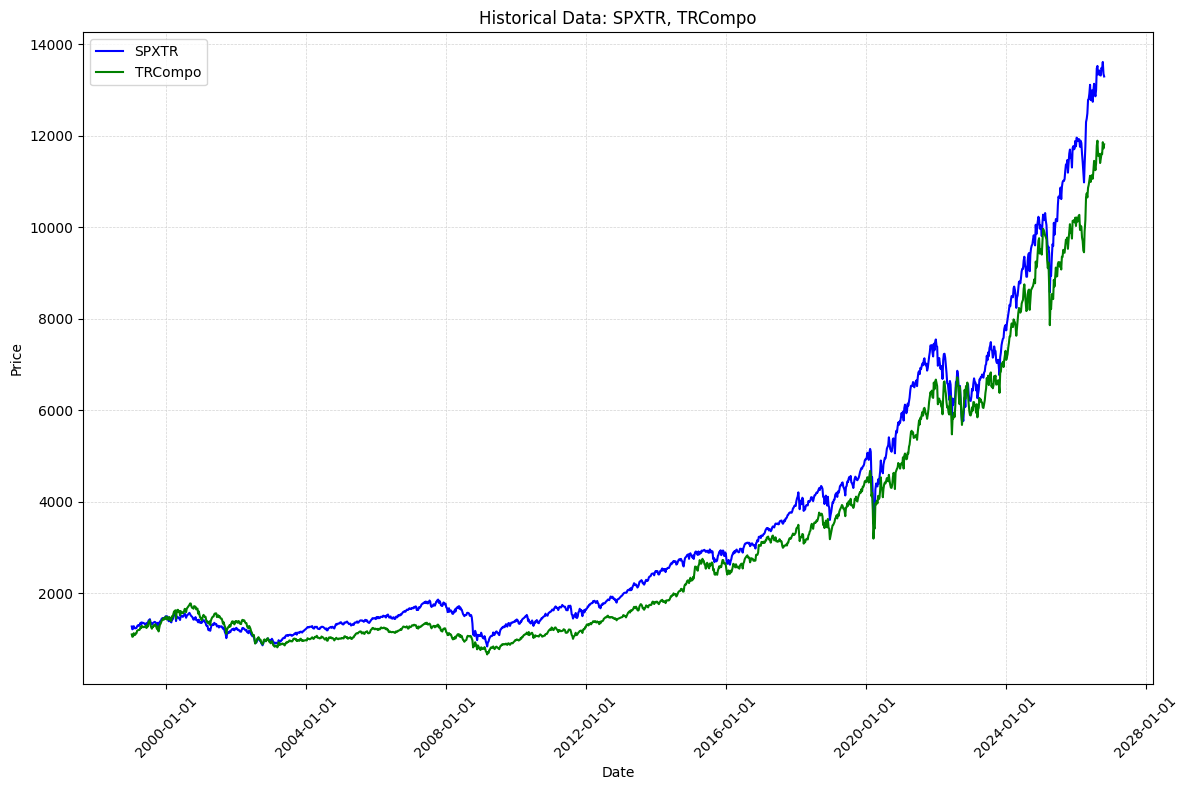

In [72]:
# Set plot style
plt.style.use('default')

# Plot the data
plt.figure(figsize=(12, 8))
plt.plot(data.index, data['SPXTR'], label='SPXTR', color='blue')
plt.plot(data.index, data['TRCompo'], label='TRCompo', color='green')

# Format the x-axis for dates
plt.gca().xaxis.set_major_locator(mdates.AutoDateLocator())  # Automatically choose appropriate ticks
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))  # Format as 'YYYY-MM-DD'

# Rotate x-axis labels for readability
plt.xticks(rotation=45)

# Add labels, title, and legend
plt.xlabel('Date')
plt.ylabel('Price')
plt.title('Historical Data: SPXTR, TRCompo')
plt.legend()

# Add gridlines
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Show the plot
plt.tight_layout()  # Adjust layout to prevent label clipping
plt.show()


In [73]:
data.describe()

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return
count,1448.000000,1448.000000,1448.000000,1448.000000,1448.000000,1448.000000,1448.000000,1448.000000
mean,2385.845180,1.182072,3505.842035,3063.855436,0.001564,-0.000056,0.001949,0.002029
std,1657.177551,0.151075,3010.658538,2712.936498,0.024509,0.012798,0.024509,0.026698
min,683.380000,0.837200,838.442584,663.587324,-0.181955,-0.053917,-0.181570,-0.163427
25%,1230.327500,1.086975,1385.557369,1157.696709,-0.010619,-0.007910,-0.010235,-0.012540
50%,1521.760000,1.167650,1910.581172,1629.660909,0.002716,-0.000000,0.003100,0.002669
75%,2970.795000,1.294625,4504.847731,4058.178641,0.014470,0.007771,0.014855,0.017156
max,7811.540000,1.594100,13614.142368,11893.396154,0.121017,0.058552,0.121402,0.161106


In [74]:
# Define the window for 5 years (assuming monthly data, this is 60 months)
WINDOW_SIZE = 260

In [75]:
# Create an empty DataFrame for storing the rolling performance
rolling_performance_5Y = pd.DataFrame(index=data.index)

# Loop through the data, starting at the index equal to WINDOW_SIZE
for i in range(WINDOW_SIZE, len(data)):
    # Use the actual Date-based index, not the integer index
    rolling_performance_5Y.loc[data.index[i], 'Rolling5YPerf'] =round( 100* ( data.loc[data.index[i], 'TRCompo'] 
                                                                      / data.loc[data.index[i-WINDOW_SIZE], 'TRCompo'] - 1),2)


rolling_performance_5Y.dropna(inplace=True)




In [76]:
rolling_performance_5Y.describe()

,Rolling5YPerf
count,1188.000000
mean,62.538645
std,59.785477
min,-38.810000
25%,-1.370000
50%,86.115000
75%,111.427500
max,184.990000


In [77]:
rolling_performance_5Y.index

DatetimeIndex(['2004-01-02', '2004-01-09', '2004-01-16', '2004-01-23',
               '2004-01-30', '2004-02-06', '2004-02-13', '2004-02-20',
               '2004-02-27', '2004-03-05',
               ...
               '2026-08-21', '2026-08-28', '2026-09-04', '2026-09-11',
               '2026-09-18', '2026-09-25', '2026-10-02', '2026-10-09',
               '2026-10-16', '2026-10-23'],
              dtype='datetime64[ns]', name='Date', length=1188, freq=None)

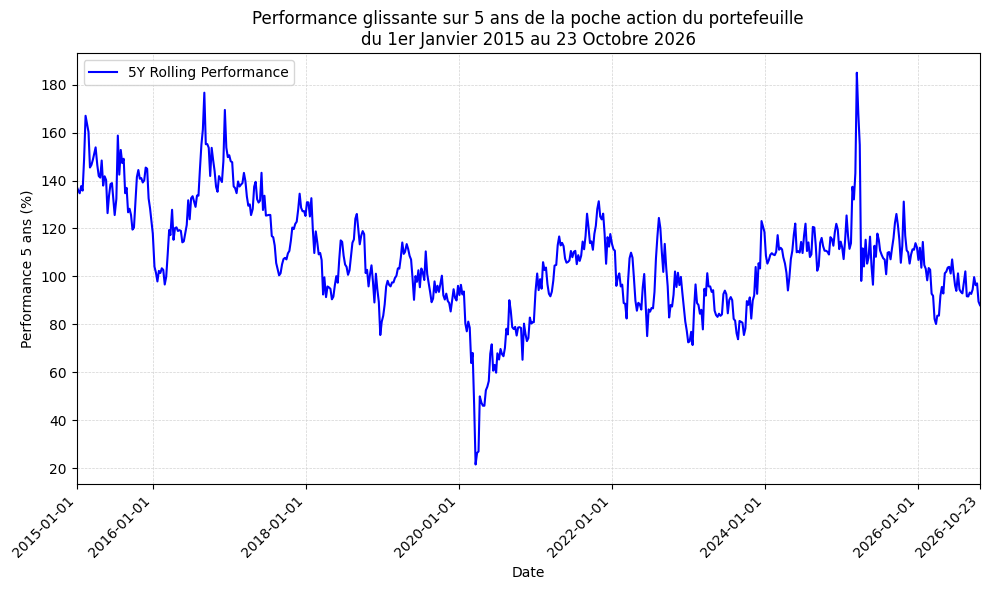

In [78]:
# Ensure the index is a datetime object
rolling_performance_5Y.index = pd.to_datetime(rolling_performance_5Y.index)

# Filtrer les données à partir du 01/01/2015
date_debut = pd.Timestamp('2015-01-01')

data_plot = rolling_performance_5Y.loc[
    rolling_performance_5Y.index >= date_debut
].sort_index()

if data_plot.empty:
    raise ValueError("Aucune donnée disponible à partir du 01/01/2015")

# Dernière date disponible
date_fin = data_plot.index.max()

# Plot the 5-year rolling performance
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    data_plot.index,
    data_plot['Rolling5YPerf'],
    label='5Y Rolling Performance',
    color='blue'
)

# Titre avec dates de début et de fin
mois_fr = [
    "Janvier", "Février", "Mars", "Avril", "Mai", "Juin",
    "Juillet", "Août", "Septembre", "Octobre", "Novembre", "Décembre"
]

def format_date_fr(date):
    jour = "1er" if date.day == 1 else str(date.day)
    return f"{jour} {mois_fr[date.month - 1]} {date.year}"

ax.set_title(
    f'Performance glissante sur 5 ans de la poche action du portefeuille\n'
    f'du {format_date_fr(date_debut)} au {format_date_fr(date_fin)}'
)

ax.set_xlabel('Date')
ax.set_ylabel('Performance 5 ans (%)')
ax.legend()

# Axe X : limites exactes
ax.set_xlim(date_debut, date_fin)

# Graduations automatiques + dates extrêmes
locator = mdates.AutoDateLocator()
ticks = locator.tick_values(date_debut, date_fin)

debut_num = mdates.date2num(date_debut)
fin_num = mdates.date2num(date_fin)

ticks = ticks[(ticks > debut_num) & (ticks < fin_num)]
ticks = np.concatenate(([debut_num], ticks, [fin_num]))

ax.set_xticks(ticks)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))

plt.xticks(rotation=45, ha='right')

# Grille
ax.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Enregistrer le graphique
plt.tight_layout()

os.makedirs("./results", exist_ok=True)

plt.savefig(
    "./results/5Y_SPX_Roll.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [79]:
rolling_performance_5Y_filtered = rolling_performance_5Y.loc[
    pd.to_datetime(rolling_performance_5Y.index) >= '2015-01-01'
].copy()

In [80]:
# Calculate the standard deviation of returns for each column
annual_volatility = round(
    rolling_performance_5Y_filtered['Rolling5YPerf'].std() / np.sqrt(5),
    2
)
annualized_median_return = round(float(rolling_performance_5Y_filtered.median().iloc[0]/5),2)
annualized_mean_return = round(float(rolling_performance_5Y_filtered.mean().iloc[0]/5),2)

# Display the standard deviation of returns
print(f"Annualized volatility of strategy: {annual_volatility}%")
print(f"Annualized Median Return of strategy: {annualized_median_return}%")
print(f"Annualized Mean Return of strategy: {annualized_mean_return}%")



Annualized volatility of strategy: 10.03%
Annualized Median Return of strategy: 21.42%
Annualized Mean Return of strategy: 21.53%


In [81]:
annual_volatility

10.03

In [82]:
OBLIG_RETURN=6
OBLIG_RATIO=0.6
combo_return= OBLIG_RATIO * OBLIG_RETURN + (1-OBLIG_RATIO)  * annualized_median_return
combo_return

12.168000000000001

In [83]:
combo_vol = round((1-OBLIG_RATIO)  * annual_volatility,2)
sharp_ratio=round(combo_return/combo_vol,2)

In [84]:
combo_return,combo_vol, sharp_ratio

(12.168000000000001, 4.01, 3.03)

# 3. ANALYSE DE LA CORRELATION entre S&P et EURUSD en crash de marche

In [85]:
# Assuming 'data' is your DataFrame, and you want to calculate correlation between 'Column1' and 'Column2'
correlation = round(data['SPX_return'].corr(data['USDEUR_return'])*100,2)

In [86]:
print(f"Correlation S&P vs EURUSD FX: {correlation}%")

Correlation S&P vs EURUSD FX: -8.37%


In [87]:
data

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return,Crash
Date,,,,,,,,,
1999-01-08,1275.09,1.1580,1275.562846,1101.522320,0.037164,0.008562,0.037549,0.046509,False
1999-01-14,1212.19,1.1560,1213.130122,1049.420521,-0.049330,0.001727,-0.048945,-0.047300,False
1999-01-22,1225.19,1.1585,1226.606793,1058.788772,0.010724,-0.002163,0.011109,0.008927,False
1999-01-29,1279.64,1.1365,1281.591530,1127.665226,0.044442,0.018990,0.044827,0.065052,False
1999-02-05,1239.40,1.1257,1241.783081,1103.120797,-0.031446,0.009503,-0.031062,-0.021766,False
...,...,...,...,...,...,...,...,...,...
2026-09-25,7743.41,1.1613,13485.073710,11612.050038,0.012144,-0.002677,0.012529,0.009826,False
2026-10-02,7722.72,1.1601,13454.228841,11597.473357,-0.002672,0.001033,-0.002287,-0.001255,False
2026-10-09,7811.54,1.1479,13614.142368,11860.042136,0.011501,0.010516,0.011886,0.022640,False


In [88]:
# Sélection des 50 plus fortes baisses hebdomadaires
worst_50 = data["SPX_return"].dropna().nsmallest(50)

# Seuil correspondant à la 50e plus forte baisse
seuil = worst_50.max()

print(f"Seuil de baisse : {seuil:.2%}")
print(f"Nombre d'observations : {len(worst_50)}")

# Corrélation S&P 500 / USD-EUR sur ces 50 semaines
crises = data.loc[
    worst_50.index,
    ["SPX_return", "USDEUR_return"]
].dropna()

correlation = crises["SPX_return"].corr(
    crises["USDEUR_return"]
)

print(f"Corrélation pendant les crises : {correlation:.2%}")
print(f"Observations utilisées : {len(crises)}")


Seuil de baisse : -4.45%
Nombre d'observations : 50
Corrélation pendant les crises : -8.77%
Observations utilisées : 50


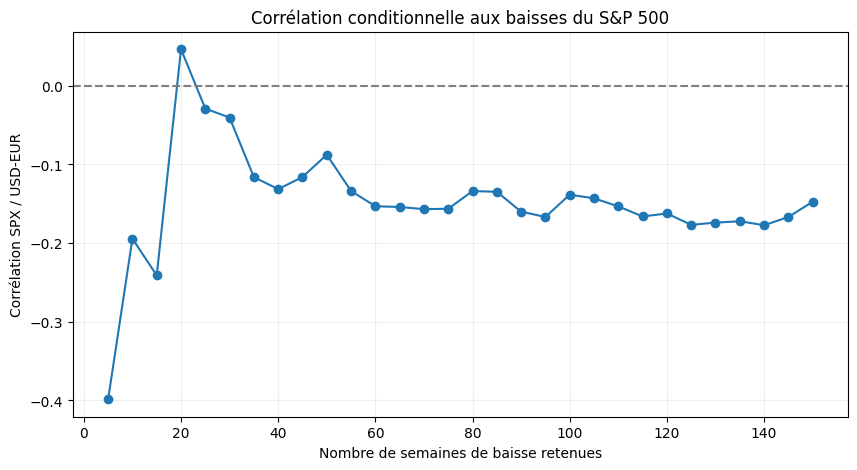

,N,Seuil SPX (%),Correlation
0,5,-10.474495,-0.398514
1,10,-8.020404,-0.194430
2,15,-6.838013,-0.241045
3,20,-6.388358,0.046408
4,25,-5.768477,-0.029086
5,30,-5.161958,-0.040503
6,35,-4.932985,-0.116238
7,40,-4.689475,-0.131436
8,45,-4.549342,-0.116006
9,50,-4.448379,-0.087739


In [89]:

df = data[["SPX_return", "USDEUR_return"]].dropna()

resultats = []

for n in range(5, 151, 5):
    crises = df.nsmallest(n, "SPX_return")

    resultats.append({
        "N": n,
        "Seuil SPX (%)": crises["SPX_return"].max() * 100,
        "Correlation": crises["SPX_return"].corr(
            crises["USDEUR_return"]
        )
    })

corr_df = pd.DataFrame(resultats)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(corr_df["N"], corr_df["Correlation"], marker="o")
ax.axhline(0, color="gray", linestyle="--")
ax.set_xlabel("Nombre de semaines de baisse retenues")
ax.set_ylabel("Corrélation SPX / USD-EUR")
ax.set_title("Corrélation conditionnelle aux baisses du S&P 500")
ax.grid(alpha=0.2)
plt.show()

display(corr_df)

,Début,Point bas,Fin,En cours,Baisse SPX (%),USD sommet -> bas (%),USD sommet -> fin (%)
0,2000-03-24,2002-10-04,2007-06-01,False,-47.59,-0.19,-27.28
1,2007-10-12,2009-03-06,2013-03-28,False,-56.24,12.28,9.06
2,2020-02-14,2020-03-20,2020-08-21,False,-31.81,-0.01,-6.34
3,2021-12-31,2022-10-14,2023-12-29,False,-24.82,16.79,5.05


Nombre de crises : 4
Appréciation moyenne du dollar (sommet -> point bas) : 7.22%
Proportion de crises avec dollar en hausse : 50.0%


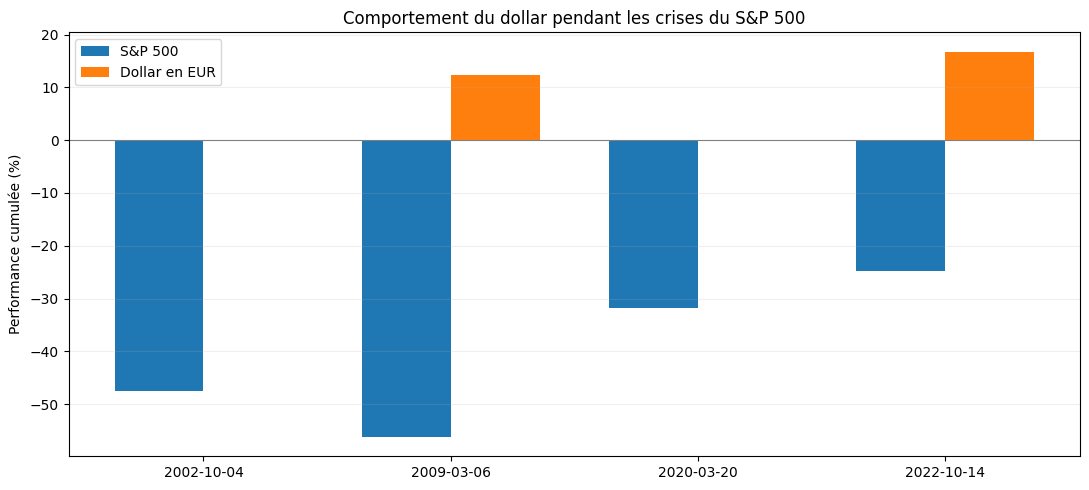

In [90]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

Path("results").mkdir(exist_ok=True)

# EURUSD = nombre de dollars pour 1 euro
# Une baisse de EURUSD signifie une appréciation du dollar
df = data[["SPX", "EURUSD"]].copy()
df.index = pd.to_datetime(df.index)
df = df.sort_index().dropna()

# 1. Identifier les crises à partir du drawdown du S&P 500
df["sommet"] = df["SPX"].cummax()
df["drawdown"] = df["SPX"] / df["sommet"] - 1

# 2. Construire les épisodes sommet -> point bas -> récupération
episodes = []
sommet_idx = 0
point_bas_idx = 0
en_baisse = False

for i in range(1, len(df)):
    if df["SPX"].iloc[i] >= df["SPX"].iloc[sommet_idx]:
        if en_baisse:
            drawdown = df["SPX"].iloc[point_bas_idx] / df["SPX"].iloc[sommet_idx] - 1

            if drawdown <= -0.20:
                episodes.append((sommet_idx, point_bas_idx, i, False))

        sommet_idx = i
        point_bas_idx = i
        en_baisse = False

    else:
        en_baisse = True

        if df["SPX"].iloc[i] < df["SPX"].iloc[point_bas_idx]:
            point_bas_idx = i

# Inclure une éventuelle crise non encore terminée
if en_baisse:
    drawdown = df["SPX"].iloc[point_bas_idx] / df["SPX"].iloc[sommet_idx] - 1

    if drawdown <= -0.20:
        episodes.append((sommet_idx, point_bas_idx, len(df)-1, True))

# 3. Calculer les performances SPX et USD/EUR par crise
resultats = []

for debut, bas, fin, en_cours in episodes:
    usd_debut = df["EURUSD"].iloc[debut]
    usd_bas = df["EURUSD"].iloc[bas]
    usd_fin = df["EURUSD"].iloc[fin]

    resultats.append({
        "Début": df.index[debut].date(),
        "Point bas": df.index[bas].date(),
        "Fin": df.index[fin].date(),
        "En cours": en_cours,
        "Baisse SPX (%)": (
            df["SPX"].iloc[bas] / df["SPX"].iloc[debut] - 1
        ) * 100,
        "USD sommet -> bas (%)": (
            usd_debut / usd_bas - 1
        ) * 100,
        "USD sommet -> fin (%)": (
            usd_debut / usd_fin - 1
        ) * 100
    })

crises_df = pd.DataFrame(resultats)

display(crises_df.round(2))

# 4. Synthèse
if not crises_df.empty:
    print("Nombre de crises :", len(crises_df))

    print(
        "Appréciation moyenne du dollar (sommet -> point bas) :",
        f"{crises_df['USD sommet -> bas (%)'].mean():.2f}%"
    )

    print(
        "Proportion de crises avec dollar en hausse :",
        f"{(crises_df['USD sommet -> bas (%)'] > 0).mean():.1%}"
    )

# 5. Graphique comparatif par crise
if not crises_df.empty:
    labels = crises_df["Point bas"].astype(str)

    fig, ax = plt.subplots(figsize=(11, 5))

    x = np.arange(len(labels))
    width = 0.36

    ax.bar(
        x - width/2,
        crises_df["Baisse SPX (%)"],
        width,
        label="S&P 500"
    )

    ax.bar(
        x + width/2,
        crises_df["USD sommet -> bas (%)"],
        width,
        label="Dollar en EUR"
    )

    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel("Performance cumulée (%)")
    ax.set_title("Comportement du dollar pendant les crises du S&P 500")
    ax.legend()
    ax.grid(axis="y", alpha=0.2)

    plt.tight_layout()
    plt.savefig(
        "results/usd_spx_crises_historiques.jpeg",
        dpi=250,
        bbox_inches="tight"
    )
    plt.show()


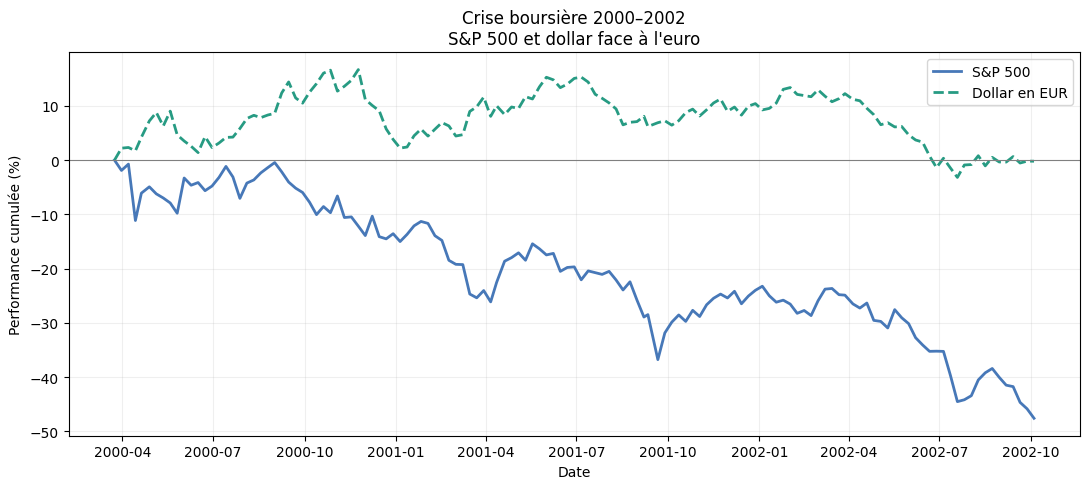

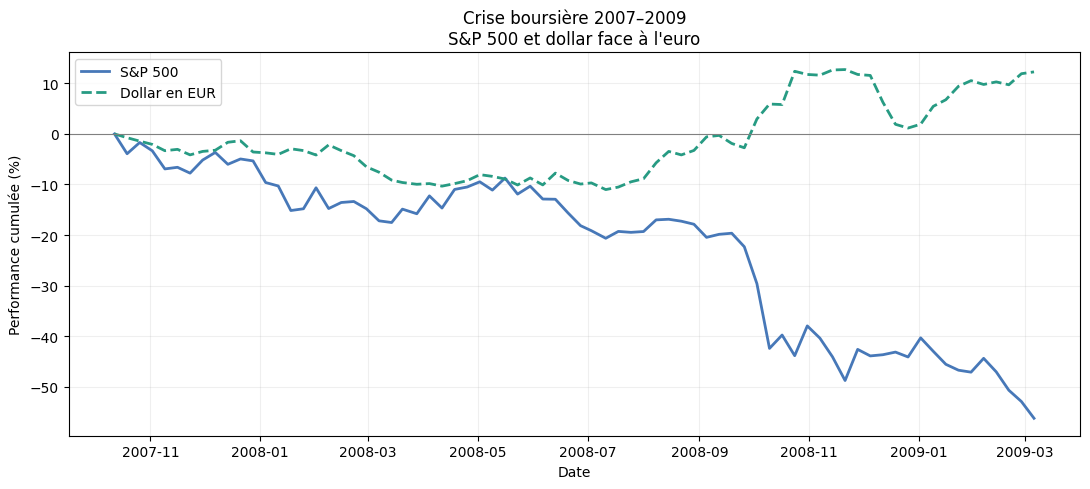

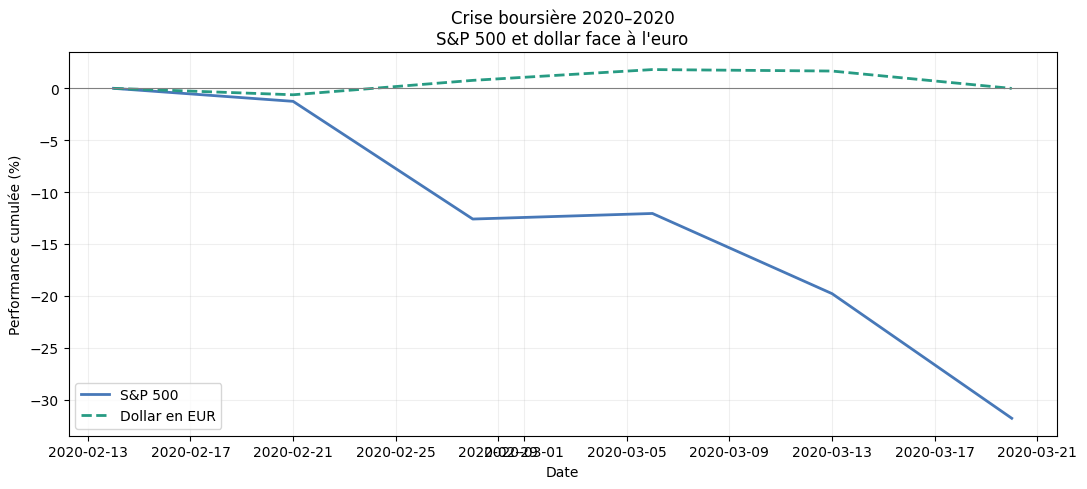

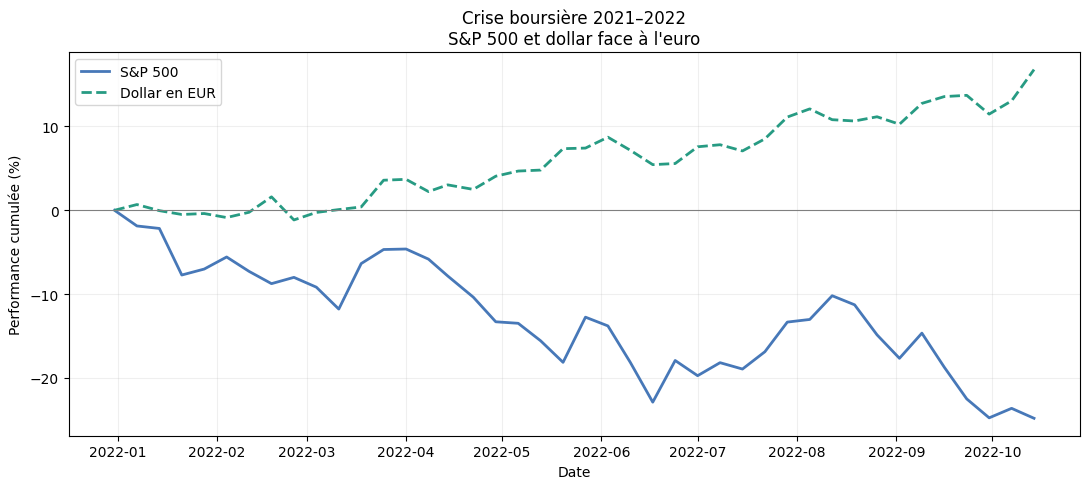

,Crise,S&P 500 (%),Hausse maximale USD (%)
0,2000–2002,-47.59 %,+16.70 %
1,2007–2009,-56.24 %,+12.73 %
2,2020–2020,-31.81 %,+1.81 %
3,2021–2022,-24.82 %,+16.79 %


In [91]:

Path("results").mkdir(parents=True, exist_ok=True)

resultats = []

for debut, bas, fin, en_cours in episodes:

    periode = df.iloc[debut:bas+1].copy()

    periode["SPX_perf"] = (
        periode["SPX"] / periode["SPX"].iloc[0] - 1
    ) * 100

    periode["USD_perf"] = (
        periode["EURUSD"].iloc[0] / periode["EURUSD"] - 1
    ) * 100

    annee_debut = periode.index[0].year
    annee_fin = periode.index[-1].year

    # Statistiques
    perf_spx = periode["SPX_perf"].iloc[-1]
    max_usd = periode["USD_perf"].max()

    resultats.append({
        "Crise": f"{annee_debut}–{annee_fin}",
        "S&P 500 (%)": perf_spx,
        "Hausse maximale USD (%)": max_usd
    })

    # Graphique individuel
    fig, ax = plt.subplots(figsize=(11, 5))

    ax.plot(
        periode.index,
        periode["SPX_perf"],
        color="#4778B8",
        linewidth=2,
        label="S&P 500"
    )

    ax.plot(
        periode.index,
        periode["USD_perf"],
        color="#279B83",
        linestyle="--",
        linewidth=2,
        label="Dollar en EUR"
    )

    ax.axhline(0, color="gray", linewidth=0.8)

    ax.set_title(
        f"Crise boursière {annee_debut}–{annee_fin}\n"
        "S&P 500 et dollar face à l'euro"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("Performance cumulée (%)")
    ax.legend()
    ax.grid(alpha=0.2)

    plt.tight_layout()

    fichier = (
        f"results/crise_spx_usd_{annee_debut}_{annee_fin}.jpeg"
    )

    plt.savefig(fichier, dpi=250, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Tableau récapitulatif unique
tableau_crises = pd.DataFrame(resultats)

display(
    tableau_crises.style.format({
        "S&P 500 (%)": "{:+.2f} %",
        "Hausse maximale USD (%)": "{:+.2f} %"
    })
)

# Export CSV
tableau_crises.to_csv(
    "results/tableau_crises_spx_usd.csv",
    index=False
)


In [92]:
# Filter the data where Crash is True
filtered_data = data[data['Crash'] == True]

# Calculate the correlation between the two columns on the filtered data
correlation = round(filtered_data['SPX_return'].corr(filtered_data['USDEUR_return'])*100,2)

# Display the correlation
print(f"Correlation between S&P and USDEUR FX during crashes: {correlation}%")


Correlation between S&P and USDEUR FX during crashes: -39.85%


In [93]:
filtered_data

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return,Crash
Date,,,,,,,,,
2000-04-14,1357.52,0.9605,1392.914205,1450.196986,-0.104745,-0.006075,-0.104360,-0.109769,True
2001-09-21,965.80,0.9139,1020.123713,1116.231221,-0.116005,0.006630,-0.115620,-0.109717,True
2008-10-10,899.22,1.3394,1094.254195,816.973417,-0.181955,0.027941,-0.181570,-0.158045,True
2020-02-28,2954.22,1.0942,4510.484131,4122.175225,-0.114907,0.013781,-0.114522,-0.102149,True
2020-03-20,2304.92,1.1027,3523.560140,3195.393253,-0.149796,-0.016754,-0.149411,-0.163427,True


# 4 COMPARISON vs. SX5E

In [94]:
data_SX5E = pd.read_excel(
    strategy_excel,
    sheet_name='vsSTOXX50E',
    skiprows=3,
    usecols=[0, 1, 4, 7]
)

# Renommer les colonnes
data_SX5E.rename(
    columns={
        'Close': 'SPX',
        'Close.1': 'EURUSD',
        'Close.2': 'SX5E'
    },
    inplace=True
)

# Convertir les dates
data_SX5E['Date'] = pd.to_datetime(
    data_SX5E['Date'], errors='coerce'
)

# Convertir les valeurs en nombres
for col in ['SPX', 'EURUSD', 'SX5E']:
    data_SX5E[col] = pd.to_numeric(data_SX5E[col], errors='coerce')

# Nettoyer et indexer
data_SX5E.dropna(inplace=True)
data_SX5E.set_index('Date', inplace=True)
data_SX5E.sort_index(inplace=True)
data_SX5E = data_SX5E.loc['2015-01-01':].copy()
print(data_SX5E.head())

                             SPX  EURUSD     SX5E
Date                                             
2015-01-02 16:00:00.288  2058.20  1.2462  3067.32
2015-01-09 16:00:00.288  2044.81  1.2227  3141.28
2015-01-16 16:00:00.288  2019.42  1.2181  3184.66
2015-01-23 16:00:00.288  2051.82  1.1998  3139.44
2015-01-30 16:00:00.288  1994.99  1.1838  3042.90


In [95]:
data_SX5E

,SPX,EURUSD,SX5E
Date,,,
2015-01-02 16:00:00.288,2058.20,1.2462,3067.32
2015-01-09 16:00:00.288,2044.81,1.2227,3141.28
2015-01-16 16:00:00.288,2019.42,1.2181,3184.66
2015-01-23 16:00:00.288,2051.82,1.1998,3139.44
2015-01-30 16:00:00.288,1994.99,1.1838,3042.90
...,...,...,...
2026-09-25 16:00:00.288,7743.41,1.1613,6236.20
2026-10-02 16:00:00.288,7722.72,1.1601,6302.82
2026-10-09 16:00:00.288,7811.54,1.1479,6238.50


In [96]:
data_SX5E['SPX_EUR'] = data_SX5E['SPX'] / data_SX5E['EURUSD']

In [97]:
data_SX5E.tail(20)

,SPX,EURUSD,SX5E,SPX_EUR
Date,,,,
2026-06-12 16:00:00.288,7431.46,1.16030,6062.07,6404.774627
2026-06-18 16:00:00.288,7500.58,1.16607,6187.63,6432.358263
2026-06-26 16:00:00.288,7354.02,1.15201,6293.13,6383.642503
2026-07-02 16:00:00.288,7483.24,1.15680,6221.55,6468.914246
2026-07-10 16:00:00.288,7575.39,1.14710,6412.68,6603.949089
2026-07-17 16:00:00.288,7457.69,1.13880,6269.97,6548.726730
2026-07-24 16:00:00.288,7411.98,1.14350,6230.87,6481.836467
2026-07-31 16:00:00.288,7489.72,1.14140,6280.94,6561.871386
2026-08-07 16:00:00.288,7757.64,1.14370,6358.01,6782.932587


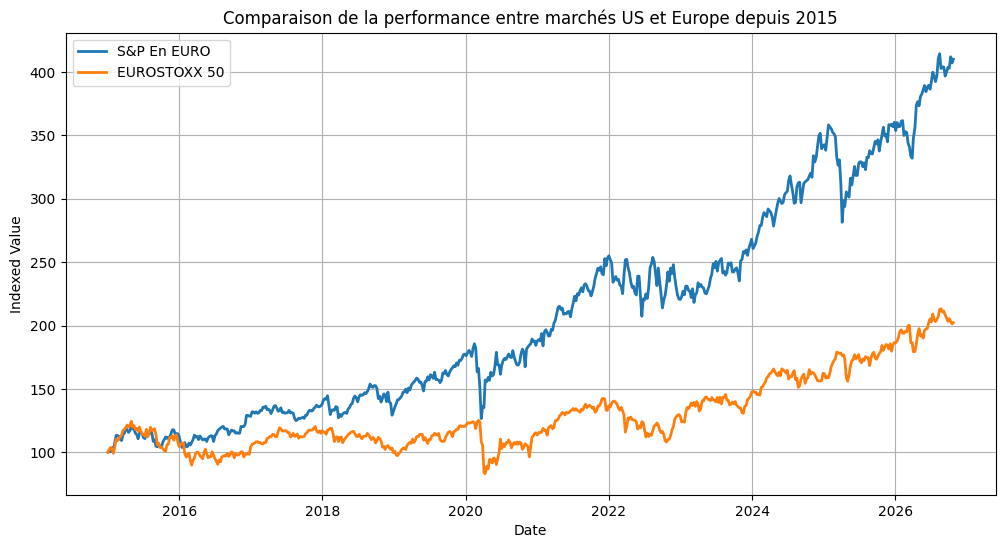

In [98]:
# Normalize both SPX_EUR and SX5E to start at 100
data_SX5E["SPX_EUR_Indexed"] = (data_SX5E["SPX_EUR"] / data_SX5E["SPX_EUR"].iloc[0]) * 100
data_SX5E["SX5E_Indexed"] = (data_SX5E["SX5E"] / data_SX5E["SX5E"].iloc[0]) * 100

# Plot the indexed values
plt.figure(figsize=(12, 6))
plt.plot(data_SX5E.index, data_SX5E["SPX_EUR_Indexed"], label="S&P En EURO", linewidth=2)
plt.plot(data_SX5E.index, data_SX5E["SX5E_Indexed"], label="EUROSTOXX 50", linewidth=2)
plt.title("Comparaison de la performance entre marchés US et Europe depuis 2015")
plt.xlabel("Date")
plt.ylabel("Indexed Value")
plt.legend()
plt.grid()
plt.savefig("./results/SPXvSSX5E.png", dpi=300, bbox_inches="tight")
plt.show()


# 5. GET HISTORICAL FED DATA FOR TBILL

In [71]:
# Replace 'your_api_key' with your actual FRED API key
fred = Fred(api_key=FED_API_KEY)

# Example: Fetching the 5-Year Treasury Constant Maturity Rate ('DGS5')
tbill_5y_data = fred.get_series('DGS5')

In [72]:
tbill_5y_data

1962-01-02    3.88
1962-01-03    3.87
1962-01-04    3.86
1962-01-05    3.89
1962-01-08    3.91
              ... 
2026-10-16    4.89
2026-10-19    4.94
2026-10-20    4.94
2026-10-21    4.95
2026-10-22    4.78
Length: 16908, dtype: float64

In [73]:
tbill_5y_data.index = pd.to_datetime(tbill_5y_data.index)

In [74]:
tbill_5y_data.dropna(inplace=True)

In [75]:
# Convert Series to DataFrame
tbill_5y_df = pd.DataFrame(tbill_5y_data)

# Optionally, rename the column for clarity
tbill_5y_df.rename(columns={tbill_5y_df.columns[0]: '5Y_TBill_Yield'}, inplace=True)


In [76]:
data.index=pd.to_datetime(data.index)

In [77]:
# Perform a left join to match the dates in the original time series with the T-Bill data
matched_data = data.join(tbill_5y_df, how='left')

In [78]:
matched_data

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return,Crash,5Y_TBill_Yield
Date,,,,,,,,,,
1999-01-08,1275.09,1.1580,1275.562846,1101.522320,0.037164,0.008562,0.037549,0.046509,False,4.72
1999-01-14,1212.19,1.1560,1213.130122,1049.420521,-0.049330,0.001727,-0.048945,-0.047300,False,4.48
1999-01-22,1225.19,1.1585,1226.606793,1058.788772,0.010724,-0.002163,0.011109,0.008927,False,4.54
1999-01-29,1279.64,1.1365,1281.591530,1127.665226,0.044442,0.018990,0.044827,0.065052,False,4.55
1999-02-05,1239.40,1.1257,1241.783081,1103.120797,-0.031446,0.009503,-0.031062,-0.021766,False,4.88
...,...,...,...,...,...,...,...,...,...,...
2026-09-18,7650.50,1.1582,13318.211021,11499.059766,-0.000846,0.008645,-0.000462,0.008255,False,4.86
2026-09-25,7743.41,1.1613,13485.073817,11612.050131,0.012144,-0.002677,0.012529,0.009826,False,4.98
2026-10-02,7722.72,1.1601,13454.228949,11597.473449,-0.002672,0.001033,-0.002287,-0.001255,False,5.06


In [79]:
tbill_5y_data.tail(50)

2026-08-12    4.38
2026-08-13    4.32
2026-08-14    4.36
2026-08-17    4.38
2026-08-18    4.37
2026-08-19    4.35
2026-08-20    4.39
2026-08-21    4.43
2026-08-24    4.41
2026-08-25    4.35
2026-08-26    4.37
2026-08-27    4.38
2026-08-28    4.48
2026-08-31    4.49
2026-09-01    4.55
2026-09-02    4.54
2026-09-03    4.52
2026-09-04    4.54
2026-09-08    4.57
2026-09-09    4.61
2026-09-10    4.75
2026-09-11    4.78
2026-09-14    4.80
2026-09-15    4.83
2026-09-16    4.86
2026-09-17    4.78
2026-09-18    4.86
2026-09-21    4.83
2026-09-22    4.83
2026-09-23    4.99
2026-09-24    5.03
2026-09-25    4.98
2026-09-28    5.06
2026-09-29    5.06
2026-09-30    5.09
2026-10-01    5.01
2026-10-02    5.06
2026-10-05    5.06
2026-10-06    5.03
2026-10-07    5.03
2026-10-08    4.99
2026-10-09    5.02
2026-10-13    5.00
2026-10-14    5.00
2026-10-15    4.91
2026-10-16    4.89
2026-10-19    4.94
2026-10-20    4.94
2026-10-21    4.95
2026-10-22    4.78
dtype: float64

In [80]:
data
data.index

DatetimeIndex(['1999-01-08', '1999-01-14', '1999-01-22', '1999-01-29',
               '1999-02-05', '1999-02-12', '1999-02-19', '1999-02-26',
               '1999-03-05', '1999-03-12',
               ...
               '2026-08-14', '2026-08-21', '2026-08-28', '2026-09-04',
               '2026-09-11', '2026-09-18', '2026-09-25', '2026-10-02',
               '2026-10-09', '2026-10-16'],
              dtype='datetime64[ns]', name='Date', length=1447, freq=None)

In [81]:
data.columns

Index(['SPX', 'EURUSD', 'SPXTR', 'TRCompo', 'SPX_return', 'USDEUR_return',
       'SPXTR_return', 'TRCompo_return', 'Crash'],
      dtype='object')

In [82]:
# Define the bond duration
DURATION = 5

# Calculate daily yield changes
matched_data['Yield_Change'] = matched_data['5Y_TBill_Yield'].diff()

# Calculate daily MTM move based on duration and yield change
matched_data['5Y_TBILL_MTM_Move'] = -DURATION * matched_data['Yield_Change']

In [83]:
matched_data.dropna(inplace=True)

In [84]:
matched_data

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return,Crash,5Y_TBill_Yield,Yield_Change,5Y_TBILL_MTM_Move
Date,,,,,,,,,,,,
1999-01-14,1212.19,1.1560,1213.130122,1049.420521,-0.049330,0.001727,-0.048945,-0.047300,False,4.48,-0.24,1.20
1999-01-22,1225.19,1.1585,1226.606793,1058.788772,0.010724,-0.002163,0.011109,0.008927,False,4.54,0.06,-0.30
1999-01-29,1279.64,1.1365,1281.591530,1127.665226,0.044442,0.018990,0.044827,0.065052,False,4.55,0.01,-0.05
1999-02-05,1239.40,1.1257,1241.783081,1103.120797,-0.031446,0.009503,-0.031062,-0.021766,False,4.88,0.33,-1.65
1999-02-12,1230.14,1.1303,1232.982885,1090.845691,-0.007471,-0.004086,-0.007087,-0.011128,False,4.96,0.08,-0.40
...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-18,7650.50,1.1582,13318.211021,11499.059766,-0.000846,0.008645,-0.000462,0.008255,False,4.86,0.08,-0.40
2026-09-25,7743.41,1.1613,13485.073817,11612.050131,0.012144,-0.002677,0.012529,0.009826,False,4.98,0.12,-0.60
2026-10-02,7722.72,1.1601,13454.228949,11597.473449,-0.002672,0.001033,-0.002287,-0.001255,False,5.06,0.08,-0.40


In [85]:
matched_data.describe()

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return,5Y_TBill_Yield,Yield_Change,5Y_TBILL_MTM_Move
count,1434.000000,1434.000000,1434.000000,1434.000000,1434.000000,1434.000000,1434.000000,1434.000000,1434.000000,1434.000000,1434.000000
mean,2387.630976,1.182587,3508.760964,3065.043463,0.001561,-0.000045,0.001945,0.002039,2.913375,0.000307,-0.001534
std,1655.709799,0.151110,3007.456161,2709.182879,0.024300,0.012811,0.024300,0.026566,1.544996,0.126827,0.634134
min,683.380000,0.837200,838.442584,663.587324,-0.181955,-0.053917,-0.181570,-0.163427,0.210000,-0.520000,-3.100000
25%,1230.202500,1.087000,1385.456098,1157.433288,-0.010620,-0.007874,-0.010235,-0.012512,1.610000,-0.080000,-0.350000
50%,1526.250000,1.168050,1927.621044,1635.181640,0.002685,-0.000000,0.003069,0.002613,2.825000,0.000000,-0.000000
75%,2971.845000,1.294850,4505.877762,4059.738273,0.014474,0.007771,0.014859,0.017136,4.140000,0.070000,0.400000
max,7811.540000,1.594100,13614.142477,11893.396249,0.121017,0.058552,0.121402,0.161106,6.770000,0.620000,2.600000


In [86]:
matched_data['5Y_TBILL_CompoEUR_MTM_Move'] = (1+ matched_data['USDEUR_return'])*(1+matched_data['5Y_TBILL_MTM_Move'])-1

In [87]:
matched_data

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return,Crash,5Y_TBill_Yield,Yield_Change,5Y_TBILL_MTM_Move,5Y_TBILL_CompoEUR_MTM_Move
Date,,,,,,,,,,,,,
1999-01-14,1212.19,1.1560,1213.130122,1049.420521,-0.049330,0.001727,-0.048945,-0.047300,False,4.48,-0.24,1.20,1.203800
1999-01-22,1225.19,1.1585,1226.606793,1058.788772,0.010724,-0.002163,0.011109,0.008927,False,4.54,0.06,-0.30,-0.301514
1999-01-29,1279.64,1.1365,1281.591530,1127.665226,0.044442,0.018990,0.044827,0.065052,False,4.55,0.01,-0.05,-0.031959
1999-02-05,1239.40,1.1257,1241.783081,1103.120797,-0.031446,0.009503,-0.031062,-0.021766,False,4.88,0.33,-1.65,-1.656177
1999-02-12,1230.14,1.1303,1232.982885,1090.845691,-0.007471,-0.004086,-0.007087,-0.011128,False,4.96,0.08,-0.40,-0.402452
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-18,7650.50,1.1582,13318.211021,11499.059766,-0.000846,0.008645,-0.000462,0.008255,False,4.86,0.08,-0.40,-0.394813
2026-09-25,7743.41,1.1613,13485.073817,11612.050131,0.012144,-0.002677,0.012529,0.009826,False,4.98,0.12,-0.60,-0.601071
2026-10-02,7722.72,1.1601,13454.228949,11597.473449,-0.002672,0.001033,-0.002287,-0.001255,False,5.06,0.08,-0.40,-0.399380


In [88]:
matched_data['strategy_return']=OBLIG_RATIO*matched_data['5Y_TBILL_CompoEUR_MTM_Move']+ (1-OBLIG_RATIO)*matched_data['TRCompo_return']

In [89]:
matched_data['strategy_return'].std()*np.sqrt(52)

2.727327077011745

In [90]:
matched_data['strategy_return'].median()*260

1.4959152703193086

In [91]:
matched_data['strategy_return']

Date
1999-01-14    0.703360
1999-01-22   -0.177337
1999-01-29    0.006845
1999-02-05   -1.002412
1999-02-12   -0.245922
                ...   
2026-09-18   -0.233586
2026-09-25   -0.356712
2026-10-02   -0.240130
2026-10-09    0.136628
2026-10-16    0.393107
Name: strategy_return, Length: 1434, dtype: float64

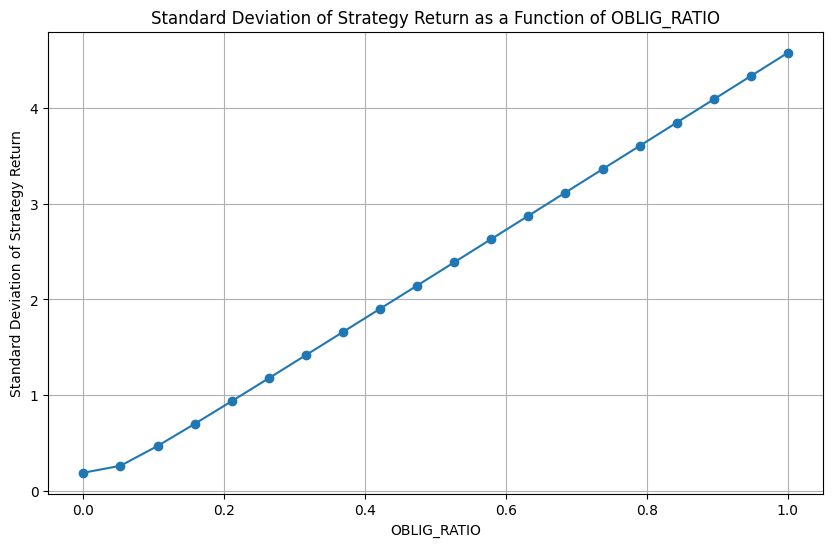

In [92]:
# Define a range of values for OBLIG_RATIO (e.g., from 0 to 1 with 0.1 increments)
oblig_ratios = np.linspace(0, 100, 20)/100
std_dev_values = []

# Loop through each OBLIG_RATIO and calculate the standard deviation of strategy_return
for ratio in oblig_ratios:
    # Calculate the strategy return for the given OBLIG_RATIO
    matched_data['strategy_return'] = (ratio * matched_data['5Y_TBILL_CompoEUR_MTM_Move'] +
                                       (1 - ratio) * matched_data['TRCompo_return'])
    # Calculate the standard deviation of the strategy return and store it
    std_dev_values.append(matched_data['strategy_return'].std()* np.sqrt(52))

# Plot OBLIG_RATIO vs. standard deviation of strategy_return
plt.figure(figsize=(10, 6))
plt.plot(oblig_ratios, std_dev_values, marker='o', linestyle='-')
plt.xlabel('OBLIG_RATIO')
plt.ylabel('Standard Deviation of Strategy Return')
plt.title('Standard Deviation of Strategy Return as a Function of OBLIG_RATIO')
plt.grid(True)
plt.show()

In [93]:
oblig_ratios

array([0.        , 0.05263158, 0.10526316, 0.15789474, 0.21052632,
       0.26315789, 0.31578947, 0.36842105, 0.42105263, 0.47368421,
       0.52631579, 0.57894737, 0.63157895, 0.68421053, 0.73684211,
       0.78947368, 0.84210526, 0.89473684, 0.94736842, 1.        ])

In [94]:
tbill_std = matched_data['5Y_TBILL_CompoEUR_MTM_Move'].std()
trcomp_std = matched_data['TRCompo_return'].std()
print(f"T-Bill Component Std: {tbill_std}, TRCompo Component Std: {trcomp_std}")


T-Bill Component Std: 0.6344056136133659, TRCompo Component Std: 0.026565583151773618


# 6. BACKTEST WITH ETF PORTFOLIO

In [100]:
strategy_excel = reload_strategy_excel()

STRATEGY_ANALYSIS rechargé avec succès


In [101]:
data_etf = pd.read_excel(
    strategy_excel,
    sheet_name='Historique',
    header=None,
    skiprows=4,
    usecols=[0, 1,  5,7]
)

data_etf.columns = ['Date', 'PSP5', 'EURUSD', 'IHYA']

data_etf['Date'] = pd.to_datetime(data_etf['Date'], errors='coerce')

for col in ['PSP5', 'IHYA', 'EURUSD']:
    data_etf[col] = pd.to_numeric(data_etf[col], errors='coerce')

data_etf = data_etf.dropna().sort_values('Date').reset_index(drop=True)

data_etf['IHYA_EUR'] = data_etf['IHYA'] / data_etf['EURUSD']

display(data_etf.head())

,Date,PSP5,EURUSD,IHYA,IHYA_EUR
0,2017-05-05 17:39:59.904,16.79,1.0996,5.03,4.574391
1,2017-05-12 17:39:59.904,16.91,1.0932,5.05,4.619466
2,2017-05-19 17:39:59.904,16.46,1.1207,5.07,4.523958
3,2017-05-26 17:39:59.904,16.71,1.1182,5.08,4.543016
4,2017-06-02 17:39:59.904,16.70,1.1283,5.10,4.520074


In [102]:
perf_etf = data_etf[['Date', 'PSP5', 'IHYA_EUR']].copy()

perf_etf['PSP5'] = perf_etf['PSP5'].pct_change(fill_method=None)
perf_etf['IHYA_EUR'] = perf_etf['IHYA_EUR'].pct_change(fill_method=None)

perf_etf = perf_etf.dropna().reset_index(drop=True)

display(perf_etf.head())

,Date,PSP5,IHYA_EUR
0,2017-05-12 17:39:59.904,0.007147,0.009854
1,2017-05-19 17:39:59.904,-0.026611,-0.020675
2,2017-05-26 17:39:59.904,0.015188,0.004213
3,2017-06-02 17:39:59.904,-0.000598,-0.005050
4,2017-06-09 17:39:59.904,0.011976,0.004177


In [103]:
OBLIG_RATIO = 0.30  # 30 % obligations, 70 % actions

perf_etf['port_perf'] = (
    perf_etf['PSP5'] * (1 - OBLIG_RATIO)
    + perf_etf['IHYA_EUR'] * OBLIG_RATIO
)

perf_etf['ref_index'] = 100 * (1 + perf_etf['port_perf']).cumprod()

In [104]:
perf_etf

,Date,PSP5,IHYA_EUR,port_perf,ref_index
0,2017-05-12 17:39:59.904,0.007147,0.009854,0.007959,100.795912
1,2017-05-19 17:39:59.904,-0.026611,-0.020675,-0.024831,98.293095
2,2017-05-26 17:39:59.904,0.015188,0.004213,0.011896,99.462350
3,2017-06-02 17:39:59.904,-0.000598,-0.005050,-0.001934,99.270006
4,2017-06-09 17:39:59.904,0.011976,0.004177,0.009636,100.226615
...,...,...,...,...,...
488,2026-09-18 17:39:59.904,0.006195,0.006580,0.006311,270.051984
489,2026-09-25 17:39:59.904,0.017787,-0.000292,0.012363,273.390709
490,2026-10-02 17:39:59.904,0.012603,0.002333,0.009522,275.993895
491,2026-10-09 17:39:59.904,0.015931,0.011675,0.014654,280.038336


In [105]:
N = 52

summary = pd.DataFrame(index=['PSP5', 'IHYA_EUR', 'port_perf'])

for col in summary.index:
    r = perf_etf[col].dropna()

    summary.loc[col, 'Mean annualisé'] = (1 + r.mean())**N - 1
    summary.loc[col, 'Median annualisé'] = (1 + r.median())**N - 1
    summary.loc[col, 'Vol annualisée'] = r.std() * np.sqrt(N)

display(summary.style.format("{:.2%}"))

,Mean annualisé,Median annualisé,Vol annualisée
PSP5,15.87%,21.84%,15.63%
IHYA_EUR,4.34%,4.50%,9.28%
port_perf,12.28%,14.38%,12.91%


In [106]:
portfolio_index = perf_etf[['Date', 'ref_index']].copy()

display(portfolio_index.head())
display(portfolio_index.tail())

,Date,ref_index
0,2017-05-12 17:39:59.904,100.795912
1,2017-05-19 17:39:59.904,98.293095
2,2017-05-26 17:39:59.904,99.462350
3,2017-06-02 17:39:59.904,99.270006
4,2017-06-09 17:39:59.904,100.226615


,Date,ref_index
488,2026-09-18 17:39:59.904,270.051984
489,2026-09-25 17:39:59.904,273.390709
490,2026-10-02 17:39:59.904,275.993895
491,2026-10-09 17:39:59.904,280.038336
492,2026-10-16 17:39:59.904,277.005828


## SCENARIOS du portefeuille

## SCENARIO base sur la backtets du poretfeuille

In [107]:
df = perf_etf.sort_values("Date").copy()
df["Date"] = pd.to_datetime(df["Date"])

start = df[["Date", "ref_index"]].dropna().copy()

end = start.rename(columns={
    "Date": "end_date",
    "ref_index": "end_index"
})

start["target_date"] = start["Date"] + pd.DateOffset(years=5)

periods = pd.merge_asof(
    start.sort_values("target_date"),
    end.sort_values("end_date"),
    left_on="target_date",
    right_on="end_date",
    direction="forward",
    tolerance=pd.Timedelta(days=10)
)

periods["return_5y"] = (
    periods["end_index"] / periods["ref_index"] - 1
)

returns = periods["return_5y"].dropna()

scenarios = returns.quantile([0.10, 0.50, 0.90])

scenarios.index = ["Défavorable", "Médian", "Favorable"]

print((scenarios * 100).round(2).astype(str) + " %")


Défavorable     62.1 %
Médian         73.19 %
Favorable      83.99 %
Name: return_5y, dtype: object


## SCENARIO base sur l'abnalyse historique du S&P et de la devise

In [108]:
df = data[["SPXTR", "EURUSD"]].copy()
df.index = pd.to_datetime(df.index)
df = df.sort_index().dropna()

# Fenêtres historiques de 3 ans
periods = df.copy()
periods["target_date"] = periods.index + pd.DateOffset(years=3)

future = df.reset_index().rename(columns={
    df.index.name or "index": "end_date",
    "SPXTR": "SPXTR_end",
    "EURUSD": "EURUSD_end"
})

periods = periods.reset_index().rename(columns={
    df.index.name or "index": "start_date"
})

periods = pd.merge_asof(
    periods.sort_values("target_date"),
    future.sort_values("end_date"),
    left_on="target_date",
    right_on="end_date",
    direction="forward",
    tolerance=pd.Timedelta(days=10)
).dropna()

# Performances cumulées sur 3 ans
periods["actions_usd"] = (
    periods["SPXTR_end"] / periods["SPXTR"] - 1
)

periods["usd_eur"] = (
    periods["EURUSD"] / periods["EURUSD_end"] - 1
)

periods

,start_date,SPXTR,EURUSD,target_date,end_date,SPXTR_end,EURUSD_end,actions_usd,usd_eur
0,1999-01-08,1275.562846,1.1580,2002-01-08,2002-01-11,1217.427733,0.8919,-0.045576,0.298352
1,1999-01-14,1213.130122,1.1560,2002-01-14,2002-01-18,1198.746142,0.8840,-0.011857,0.307692
2,1999-01-22,1226.606793,1.1585,2002-01-22,2002-01-25,1205.266949,0.8642,-0.017397,0.340546
3,1999-01-29,1281.591530,1.1365,2002-01-29,2002-02-01,1193.946701,0.8617,-0.068387,0.318904
4,1999-02-05,1241.783081,1.1257,2002-02-05,2002-02-08,1166.764907,0.8714,-0.060412,0.291829
...,...,...,...,...,...,...,...,...,...
1286,2023-09-22,7084.078237,1.0796,2026-09-22,2026-09-25,13485.073710,1.1613,0.903575,-0.070352
1287,2023-09-29,7034.312559,1.0712,2026-09-29,2026-10-02,13454.228841,1.1601,0.912657,-0.076631
1288,2023-10-06,7070.565176,1.0672,2026-10-06,2026-10-09,13614.142368,1.1479,0.925467,-0.070302
1289,2023-10-13,7104.924521,1.0671,2026-10-13,2026-10-16,13354.294988,1.1390,0.879583,-0.063126


In [109]:
# Hypothèse : rendement obligataire 8 % par an
bond_growth = 1.08 ** 3

# Portefeuille 40 % actions / 60 % obligations,
# sans rééquilibrage
periods["port_3y"] = (
    (
        0.4 * (1 + periods["actions_usd"])
        + 0.6 * bond_growth
    )
    * (1 + periods["usd_eur"])
    - 1
)

# Quantiles historiques
q = periods["port_3y"].quantile([0.10, 0.50, 0.90])

scenarios = pd.DataFrame({
    "Performance 3 ans": q.to_numpy(),
    "Annualisée": ((1 + q) ** (1/3) - 1).to_numpy()
}, index=["Défavorable", "Médian", "Favorable"])

print((scenarios * 100).round(2))

             Performance 3 ans  Annualisée
Défavorable              -7.35       -2.51
Médian                   32.09        9.72
Favorable                54.01       15.48


In [110]:

import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------------
# 1. Scénarios historiques à 5 ans
# ----------------------------------------

df = perf_etf[["Date", "ref_index"]].copy()
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").dropna()

start = df.copy()
start["target_date"] = start["Date"] + pd.DateOffset(years=5)

end = df.rename(columns={
    "Date": "end_date",
    "ref_index": "end_index"
})

periods_5y = pd.merge_asof(
    start.sort_values("target_date"),
    end.sort_values("end_date"),
    left_on="target_date",
    right_on="end_date",
    direction="forward",
    tolerance=pd.Timedelta(days=10)
).dropna()

returns_5y = (
    periods_5y["end_index"] / periods_5y["ref_index"] - 1
)

q5 = returns_5y.quantile([0.10, 0.50, 0.90])

scenarios_5y = pd.DataFrame({
    "Performance 5 ans": q5.to_numpy(),
    "Annualisée": ((1 + q5) ** (1/5) - 1).to_numpy()
}, index=["Défavorable", "Médian", "Favorable"])


# ----------------------------------------
# 2. Fonction d'export JPEG
# ----------------------------------------

def exporter_scenarios(df, titre, sous_titre, fichier):

    # Récupère automatiquement les colonnes du DataFrame
    tableau = df.copy()

    for col in tableau.columns:
        tableau[col] = tableau[col].map(lambda x: f"{x:+.2%}")

    fig, ax = plt.subplots(figsize=(10, 3.4))
    ax.axis("off")

    table = ax.table(
        cellText=tableau.reset_index().values,
        colLabels=["Scénario"] + list(tableau.columns),
        cellLoc="center",
        colLoc="center",
        bbox=[0.02, 0.16, 0.96, 0.58]
    )

    table.auto_set_font_size(False)
    table.set_fontsize(12)

    for (r, c), cell in table.get_celld().items():
        cell.set_edgecolor("#D9E1EA")
        if r == 0:
            cell.set_facecolor("#17365D")
            cell.set_text_props(color="white", weight="bold")
        else:
            cell.set_facecolor(
                "#F1F5FA" if r % 2 else "white"
            )

    fig.text(
        0.5, 0.92, titre,
        ha="center", fontsize=17,
        weight="bold", color="#17365D"
    )

    fig.text(
        0.5, 0.82, sous_titre,
        ha="center", fontsize=10,
        color="#526477"
    )

    fig.savefig(
        fichier,
        dpi=200,
        format="jpeg",
        bbox_inches="tight",
        facecolor="white"
    )
    plt.close(fig)


# ----------------------------------------
# 3. Export des deux tableaux
# ----------------------------------------

exporter_scenarios(
    scenarios_5y,
    "Scénarios historiques à 5 ans",
    "Portefeuille ETF 60/40 — Backtest",
    "scenarios_historiques_5_ans.jpeg"
)

exporter_scenarios(
    scenarios,
    "Scénarios prospectifs à 3 ans",
    "60 % obligations USD à 8 % / 40 % actions US",
    "scenarios_prospectifs_3_ans.jpeg"
)

display(scenarios_5y)
display(scenarios)


,Performance 5 ans,Annualisée
Défavorable,0.621013,0.101431
Médian,0.731864,0.116099
Favorable,0.839943,0.129694


,Performance 3 ans,Annualisée
Défavorable,-0.073498,-0.025125
Médian,0.320914,0.097214
Favorable,0.540141,0.154836


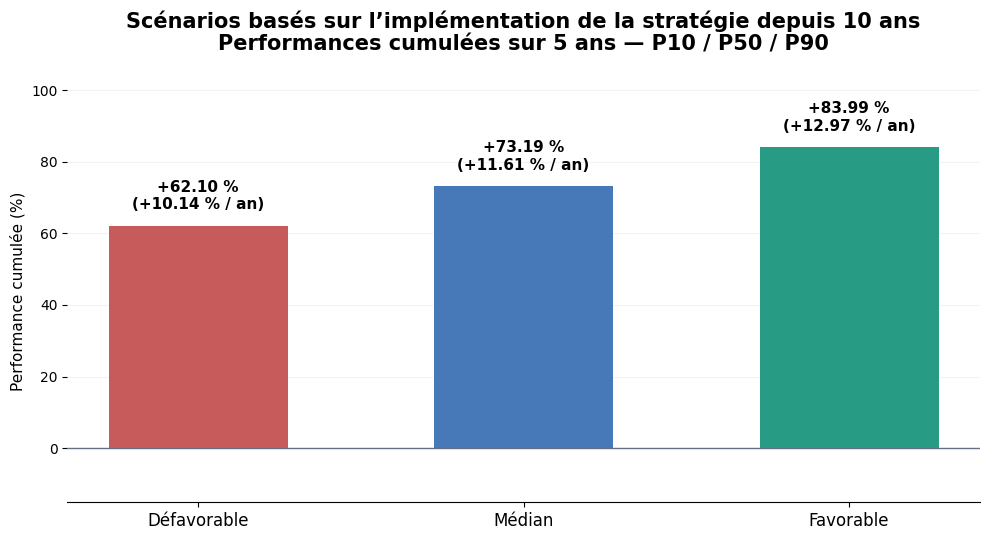

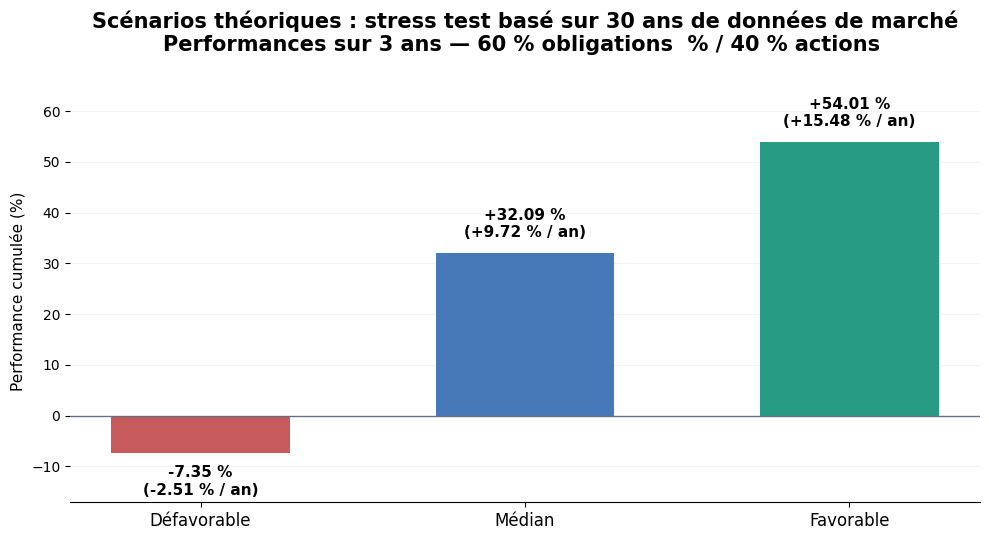

In [111]:

import matplotlib.pyplot as plt
import numpy as np

def exporter_bar_chart(df, titre, sous_titre, fichier):
    # Première colonne = performance cumulée
    performances = df.iloc[:, 0] * 100
    labels = df.index.astype(str)
    annualisees = df["Annualisée"] * 100

    couleurs = ["#C75B5B", "#4778B8", "#279B83"]

    fig, ax = plt.subplots(figsize=(10, 5.5))

    x = np.arange(len(df))
    bars = ax.bar(
        x, performances,
        color=couleurs[:len(df)],
        width=0.55
    )

    ax.axhline(0, color="#667085", linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=12)
    ax.set_ylabel("Performance cumulée (%)", fontsize=11)

    # Étiquettes des performances
    amplitude = max(abs(performances).max(), 1)
    marge = amplitude * 0.045

    for bar, perf, annualisee in zip(
        bars, performances, annualisees
    ):
        y = perf + marge if perf >= 0 else perf - marge

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            y,
            f"{perf:+.2f} %\n({annualisee:+.2f} % / an)",
            ha="center",
            va="bottom" if perf >= 0 else "top",
            fontsize=11,
            fontweight="bold"
        )

    ax.set_ylim(
        min(0, performances.min()) - amplitude * 0.18,
        max(0, performances.max()) + amplitude * 0.22
    )

    ax.set_title(
        titre + "\n" + sous_titre,
        fontsize=15,
        fontweight="bold",
        pad=22
    )

    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

    fig.tight_layout()
    fig.savefig(
        fichier,
        dpi=250,
        format="jpeg",
        bbox_inches="tight",
        facecolor="white"
    )
    plt.show()
    plt.close(fig)



from pathlib import Path

Path("results").mkdir(parents=True, exist_ok=True)

exporter_bar_chart(
    scenarios_5y,
    "Scénarios basés sur l’implémentation de la stratégie depuis 10 ans",
    "Performances cumulées sur 5 ans — P10 / P50 / P90",
    "results/scenarios_historiques_5_ans.jpeg"
)

exporter_bar_chart(
    scenarios,
    "Scénarios théoriques : stress test basé sur 30 ans de données de marché",
    "Performances sur 3 ans — 60 % obligations  % / 40 % actions ",
    "results/scenarios_prospectifs_3_ans.jpeg"
)



# 7. PORTFOLIO WEIGHTS OPTIMIZATION

In [ ]:
portfolio_daily_returns_opt=daily_returns_etf.drop(columns='EURUSD')

# Define the risk-free rate (adjust to your data)
risk_free_rate = 0.0

# Calculate mean returns and covariance matrix
mean_returns = portfolio_daily_returns_opt.mean()
cov_matrix = portfolio_daily_returns_opt.cov()

# Number of assets
num_assets = len(portfolio_daily_returns_opt.columns)

# Initial guess for weights
initial_weights = np.array([1 / num_assets] * num_assets)

# Define portfolio return and volatility
def portfolio_performance(weights, mean_returns, cov_matrix):
    portfolio_return = np.sum(weights * mean_returns)
    portfolio_volatility = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    return portfolio_return, portfolio_volatility

# Objective function: negative Sharpe ratio
def negative_sharpe_ratio(weights, mean_returns, cov_matrix, risk_free_rate):
    portfolio_return, portfolio_volatility = portfolio_performance(weights, mean_returns, cov_matrix)
    sharpe_ratio = (portfolio_return - risk_free_rate) / portfolio_volatility
    return -sharpe_ratio

# Constraints: weights sum to 1
constraints = ({'type': 'eq', 'fun': lambda weights: np.sum(weights) - 1})

# Bounds: weights between 0 and 1
bounds = tuple((0, 1) for _ in range(num_assets))

# Optimize weights
result = minimize(
    fun=negative_sharpe_ratio,
    x0=initial_weights,
    args=(mean_returns, cov_matrix, risk_free_rate),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)

# Extract optimal weights
optimal_weights = result.x

# Display results
print("Optimal Weights:", optimal_weights)
print("Maximum Sharpe Ratio:", -result.fun)


# 8. ANALYSE JP MORGAN STRATEGY

In [112]:
#jp_opcvm_hist = yf.Ticker("0P0001K15I").history(period="3y")

#print("Nombre de lignes :", len(jp_opcvm_hist))
#display(jp_opcvm_hist.head())

#  FINALEMENT ON TELECHARGE DEPUIS INVESTING https://fr.investing.com/funds/lu1283473053-historical-data

In [113]:
strategy_excel = reload_strategy_excel()

jp_opcvm_hist = pd.read_excel(
    strategy_excel,
    sheet_name='JPMORGAN',
    usecols="A:B"
)

jp_opcvm_hist.columns = ['Date', 'JP_OPCVM']

jp_opcvm_hist['Date'] = pd.to_datetime(
    jp_opcvm_hist['Date'],
    dayfirst=True
)

jp_opcvm_hist['JP_OPCVM'] = pd.to_numeric(
    jp_opcvm_hist['JP_OPCVM'],
    errors='coerce'
)

jp_opcvm_hist = jp_opcvm_hist.sort_values('Date').reset_index(drop=True)
jp_opcvm_hist['ref_index'] = (
    100 * jp_opcvm_hist['JP_OPCVM'] / jp_opcvm_hist['JP_OPCVM'].iloc[0]
)

display(jp_opcvm_hist.head())

STRATEGY_ANALYSIS rechargé avec succès


,Date,JP_OPCVM,ref_index
0,2017-05-10,104.98,100.000000
1,2017-05-17,104.90,99.923795
2,2017-05-24,104.66,99.695180
3,2017-05-31,104.88,99.904744
4,2017-06-07,105.11,100.123833


In [114]:
# Rendements entre deux valeurs liquidatives
r = jp_opcvm_hist['JP_OPCVM'].pct_change(fill_method=None).dropna()

N = 52

jp_analytics = pd.DataFrame({
    'Mean annualisé': [(1 + r.mean())**N - 1],
    'Median annualisé': [(1 + r.median())**N - 1],
    'Vol annualisée': [r.std() * np.sqrt(N)],
    'CAGR': [(jp_opcvm_hist['JP_OPCVM'].iloc[-1] /
              jp_opcvm_hist['JP_OPCVM'].iloc[0]) **
             (365.25 / (jp_opcvm_hist['Date'].iloc[-1] -
                        jp_opcvm_hist['Date'].iloc[0]).days) - 1]
}, index=['JPMORGAN'])

display(jp_analytics.style.format("{:.2%}"))

,Mean annualisé,Median annualisé,Vol annualisée,CAGR
JPMORGAN,2.21%,4.47%,4.82%,2.48%


Début : 2017-05-12
Fin   : 2026-10-16
Nombre de points : 492


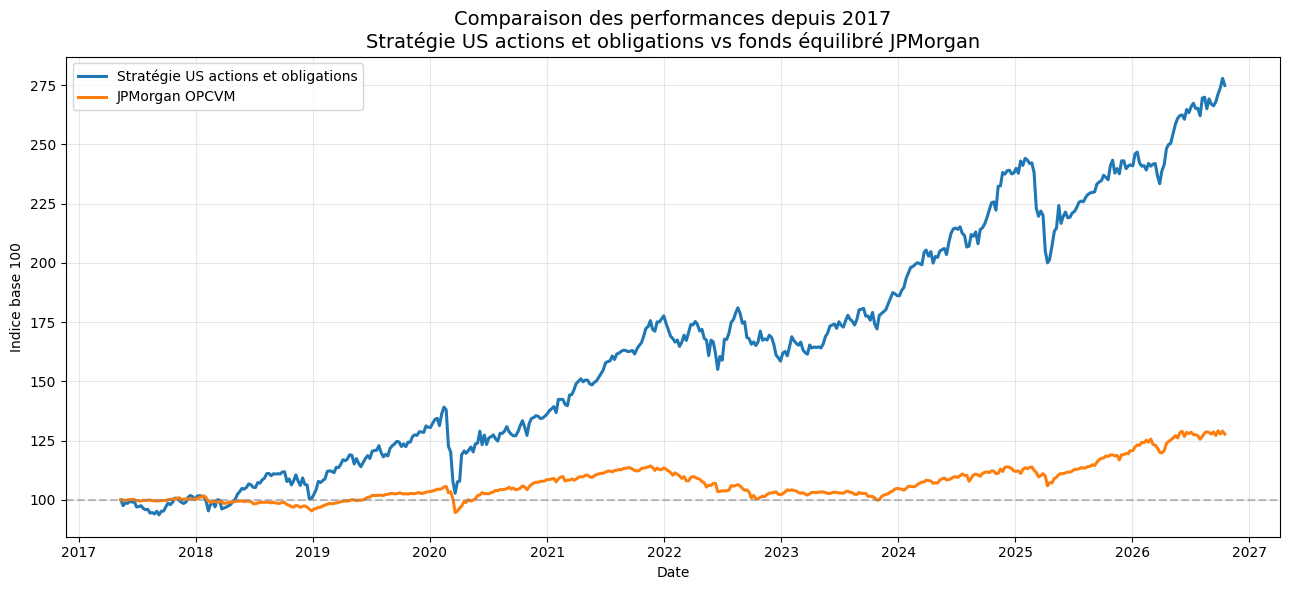


Fichiers enregistrés :
PNG : /Users/alamazou/code/d1quant/gestion_patrimoine/results/comparaison_portfolio_jpmorgan.png (322,486 octets)
PDF : /Users/alamazou/code/d1quant/gestion_patrimoine/results/comparaison_portfolio_jpmorgan.pdf (26,413 octets)


In [115]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# =====================================================
# 1. PRÉPARER LES DEUX INDICES
# =====================================================

port = portfolio_index[['Date', 'ref_index']].copy()
jp = jp_opcvm_hist[['Date', 'ref_index']].copy()

port.columns = ['Date', 'Portfolio']
jp.columns = ['Date', 'JPMorgan']

# Convertir et normaliser les dates
port['Date'] = pd.to_datetime(port['Date']).dt.normalize()
jp['Date'] = pd.to_datetime(jp['Date']).dt.normalize()

# Supprimer les valeurs manquantes
port = port.dropna().sort_values('Date')
jp = jp.dropna().sort_values('Date')

# Éliminer les dates en double
port = port.drop_duplicates('Date', keep='last')
jp = jp.drop_duplicates('Date', keep='last')

# =====================================================
# 2. ALIGNER LES DATES
# =====================================================

# Ne garder que la période commune
start_date = max(port['Date'].min(), jp['Date'].min())
end_date = min(port['Date'].max(), jp['Date'].max())

port = port[
    (port['Date'] >= start_date) &
    (port['Date'] <= end_date)
].copy()

# Aligner les VL JPMorgan sur les dates du portefeuille
comparison = pd.merge_asof(
    port,
    jp,
    on='Date',
    direction='backward',
    tolerance=pd.Timedelta(days=7)
)

comparison = comparison.dropna().reset_index(drop=True)

if comparison.empty:
    raise ValueError("Aucune date commune trouvée entre les deux indices.")

# =====================================================
# 3. REBASER LES DEUX INDICES À 100
# =====================================================

comparison['Portfolio'] = (
    100 * comparison['Portfolio'] /
    comparison['Portfolio'].iloc[0]
)

comparison['JPMorgan'] = (
    100 * comparison['JPMorgan'] /
    comparison['JPMorgan'].iloc[0]
)

print("Début :", comparison['Date'].iloc[0].date())
print("Fin   :", comparison['Date'].iloc[-1].date())
print("Nombre de points :", len(comparison))

# =====================================================
# 4. CRÉER LE GRAPHIQUE
# =====================================================

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    comparison['Date'],
    comparison['Portfolio'],
    label='Stratégie US actions et obligations',
    linewidth=2.2
)

ax.plot(
    comparison['Date'],
    comparison['JPMorgan'],
    label='JPMorgan OPCVM',
    linewidth=2.2
)

ax.axhline(
    100,
    color='gray',
    linestyle='--',
    alpha=0.5
)

ax.set_title(
    'Comparaison des performances depuis 2017\n'
    'Stratégie US actions et obligations vs fonds équilibré JPMorgan',
    fontsize=14
)

ax.set_xlabel('Date')
ax.set_ylabel('Indice base 100')

ax.legend(loc='upper left')
ax.grid(alpha=0.3)

fig.tight_layout()

# =====================================================
# 5. ENREGISTRER DANS RESULTS
# =====================================================

results_dir = Path.cwd() / 'results'
results_dir.mkdir(parents=True, exist_ok=True)

png_file = results_dir / 'comparaison_portfolio_jpmorgan.png'
pdf_file = results_dir / 'comparaison_portfolio_jpmorgan.pdf'

# Sauvegarder AVANT plt.show()
fig.savefig(
    png_file,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

fig.savefig(
    pdf_file,
    bbox_inches='tight',
    facecolor='white'
)

# =====================================================
# 6. AFFICHER ET VÉRIFIER
# =====================================================

plt.show()

print("\nFichiers enregistrés :")
print(f"PNG : {png_file} ({png_file.stat().st_size:,} octets)")
print(f"PDF : {pdf_file} ({pdf_file.stat().st_size:,} octets)")